In [ ]:
# Install required libraries
!pip install -q librosa soundfile scikit-learn


In [ ]:

# Import required libraries

import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)
print("Librosa version:", librosa.__version__)


Libraries imported successfully!
TensorFlow version: 2.21.0
Librosa version: 0.11.0


In [ ]:

# Install TensorFlow Datasets
!pip install -q tensorflow-datasets


In [ ]:

!pip install -q importlib_resources


KGAT_b95beda7eed47636e8eada671bf0f15e api

In [14]:

!pip install -q -U kaggle

from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle authentication configured!")


Kaggle authentication configured!


In [15]:

!kaggle datasets download \
    -d andradaolteanu/gtzan-dataset-music-genre-classification \
    -p /content/gtzan \
    --unzip


Dataset URL: https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification
License(s): other
100% 1.21G/1.21G [00:09<00:00, 133MB/s]



In [16]:

import os

dataset_path = "/content/gtzan"

print("Main folders and files:")

for item in os.listdir(dataset_path):
    print(item)

print("\nSearching for audio files...")

audio_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(".wav"):
            audio_files.append(os.path.join(root, file))

print("\nTotal audio files found:", len(audio_files))

print("\nFirst 5 audio files:")
for file in audio_files[:5]:
    print(file)


Main folders and files:
Data

Searching for audio files...

Total audio files found: 1000

First 5 audio files:
/content/gtzan/Data/genres_original/country/country.00017.wav
/content/gtzan/Data/genres_original/country/country.00080.wav
/content/gtzan/Data/genres_original/country/country.00053.wav
/content/gtzan/Data/genres_original/country/country.00072.wav
/content/gtzan/Data/genres_original/country/country.00034.wav


In [17]:

import os

genre_path = "/content/gtzan/Data/genres_original"

genres = sorted([
    folder for folder in os.listdir(genre_path)
    if os.path.isdir(os.path.join(genre_path, folder))
])

print("Total genres:", len(genres))
print("\nGenre-wise audio file count:\n")

for genre in genres:
    folder_path = os.path.join(genre_path, genre)
    files = [f for f in os.listdir(folder_path) if f.endswith(".wav")]
    print(f"{genre}: {len(files)} audio files")


Total genres: 10

Genre-wise audio file count:

blues: 100 audio files
classical: 100 audio files
country: 100 audio files
disco: 100 audio files
hiphop: 100 audio files
jazz: 100 audio files
metal: 100 audio files
pop: 100 audio files
reggae: 100 audio files
rock: 100 audio files


Audio loaded successfully!
Sample rate: 22050
Audio duration: 10.0 seconds
Audio shape: (220500,)


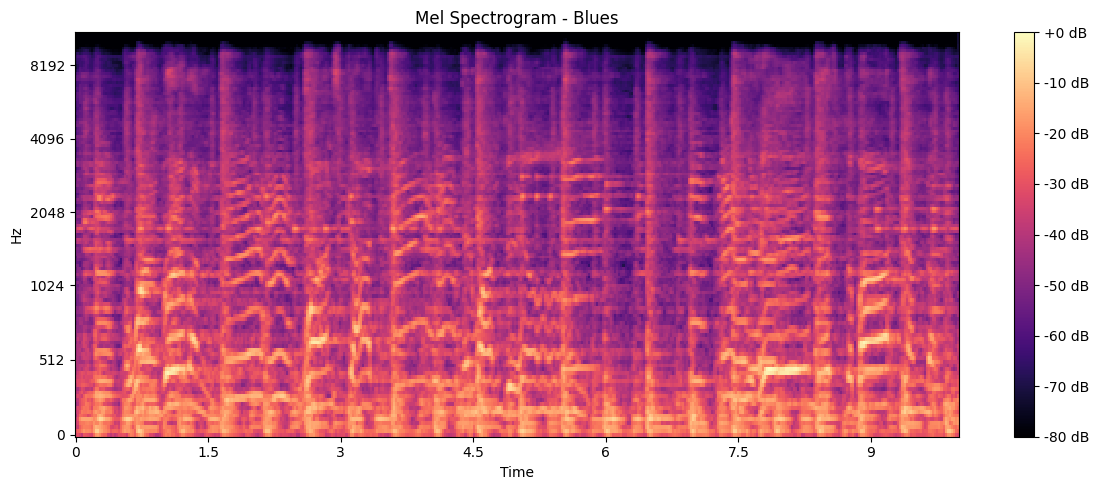

In [18]:

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# Select one audio file
audio_path = "/content/gtzan/Data/genres_original/blues/blues.00000.wav"

# Load audio
y, sr = librosa.load(audio_path, sr=22050, duration=10)

print("Audio loaded successfully!")
print("Sample rate:", sr)
print("Audio duration:", len(y) / sr, "seconds")
print("Audio shape:", y.shape)

# Extract Mel Spectrogram
mel_spec = librosa.feature.melspectrogram(
    y=y,
    sr=sr,
    n_mels=128,
    n_fft=2048,
    hop_length=512
)

# Convert to decibels
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

# Visualize Mel Spectrogram
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mel_spec_db,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram - Blues")
plt.tight_layout()
plt.show()


In [20]:
import os
import numpy as np
import librosa

dataset_path = "/content/gtzan/Data/genres_original"

X = []
y = []

genres = sorted(os.listdir(dataset_path))

for genre in genres:
    genre_folder = os.path.join(dataset_path, genre)

    for file in os.listdir(genre_folder):
        if file.endswith(".wav"):
            file_path = os.path.join(genre_folder, file)

            try:
                audio, sr = librosa.load(
                    file_path,
                    sr=22050,
                    duration=10
                )

                mel_spec = librosa.feature.melspectrogram(
                    y=audio,
                    sr=sr,
                    n_mels=128,
                    n_fft=2048,
                    hop_length=512
                )

                mel_spec_db = librosa.power_to_db(
                    mel_spec,
                    ref=np.max
                )

                X.append(mel_spec_db)
                y.append(genre)

            except Exception as e:
                print("Error:", file_path, e)

print("Feature extraction completed!")
print("Total features:", len(X))
print("Total labels:", len(y))
print("Feature shape:", X[0].shape)

/tmp/ipykernel_1056/1288760602.py:20: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Error: /content/gtzan/Data/genres_original/jazz/jazz.00054.wav 
Feature extraction completed!
Total features: 999
Total labels: 999
Feature shape: (128, 431)


In [21]:
from collections import Counter

genre_counts = Counter(y)

print("Extracted files per genre:\n")

for genre, count in sorted(genre_counts.items()):
    print(f"{genre}: {count}")

print("\nTotal extracted files:", len(X))
print("Total labels:", len(y))

Extracted files per genre:

blues: 100
classical: 100
country: 100
disco: 100
hiphop: 100
jazz: 99
metal: 100
pop: 100
reggae: 100
rock: 100

Total extracted files: 999
Total labels: 999


In [22]:
from sklearn.preprocessing import LabelEncoder

# Convert genre names into numerical labels
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Genre encoding:")

for genre, number in zip(
    label_encoder.classes_,
    range(len(label_encoder.classes_))
):
    print(f"{genre}: {number}")

print("\nEncoded labels shape:", y_encoded.shape)
print("Total classes:", len(label_encoder.classes_))

Genre encoding:
blues: 0
classical: 1
country: 2
disco: 3
hiphop: 4
jazz: 5
metal: 6
pop: 7
reggae: 8
rock: 9

Encoded labels shape: (999,)
Total classes: 10


In [23]:
# Check the shape of all Mel Spectrograms

shapes = [feature.shape for feature in X]

unique_shapes = set(shapes)

print("Unique feature shapes:", unique_shapes)
print("Total unique shapes:", len(unique_shapes))

Unique feature shapes: {(128, 431)}
Total unique shapes: 1


In [24]:
# Convert features into a NumPy array
X = np.array(X)

# Add a channel dimension for CNN
X = X[..., np.newaxis]

print("CNN input shape:", X.shape)
print("Labels shape:", y_encoded.shape)

CNN input shape: (999, 128, 431, 1)
Labels shape: (999,)


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (799, 128, 431, 1)
Testing data shape: (200, 128, 431, 1)

Training labels shape: (799,)
Testing labels shape: (200,)


In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)

model = Sequential([
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(128, 431, 1)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.3),

    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 429, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 429, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 214, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 212, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 212, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 106, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 104, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 104, 128)   │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 52, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 93184)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,927,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,022,538 (45.86 MB)

 Trainable params: 12,022,090 (45.86 MB)

 Non-trainable params: 448 (1.75 KB)

In [27]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [28]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 132s 6s/step - accuracy: 0.1534 - loss: 15.6530 - val_accuracy: 0.1000 - val_loss: 52.4080
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 125s 6s/step - accuracy: 0.1002 - loss: 2.2451 - val_accuracy: 0.1312 - val_loss: 22.3605
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 124s 6s/step - accuracy: 0.1252 - loss: 2.2250 - val_accuracy: 0.1312 - val_loss: 7.4633
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 126s 6s/step - accuracy: 0.2160 - loss: 2.1059 - val_accuracy: 0.1250 - val_loss: 2.4912
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 138s 6s/step - accuracy: 0.2567 - loss: 2.0221 - val_accuracy: 0.1688 - val_loss: 2.3874
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 121s 6s/step - accuracy: 0.2660 - loss: 1.9718 - val_accuracy: 0.1562 - val_loss: 2.8886
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 125s 6s/step - accuracy: 0.3146 - loss: 1.8845 - val_accuracy: 0.2062 - val_loss: 2.1973
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 124s 6s/step - accuracy: 0.3020 - loss: 1.9479 - val_accuracy: 0.1875 

In [29]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 788ms/step - accuracy: 0.2700 - loss: 3.6986

Test Loss: 3.6986215114593506
Test Accuracy: 27.000001072883606 %


In [30]:
from sklearn.metrics import classification_report
import numpy as np

# Predict genres for test data
y_pred_prob = model.predict(X_test)

# Convert probabilities into genre numbers
y_pred = np.argmax(y_pred_prob, axis=1)

# Generate classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
)

print("Classification Report:\n")
print(report)

7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step
Classification Report:

              precision    recall  f1-score   support

       blues       0.17      0.05      0.08        20
   classical       0.45      0.25      0.32        20
     country       0.09      0.10      0.09        20
       disco       0.07      0.10      0.09        20
      hiphop       0.44      0.40      0.42        20
        jazz       0.00      0.00      0.00        20
       metal       0.43      0.95      0.59        20
         pop       0.31      0.20      0.24        20
      reggae       0.36      0.20      0.26        20
        rock       0.20      0.45      0.27        20

    accuracy                           0.27       200
   macro avg       0.25      0.27      0.24       200
weighted avg       0.25      0.27      0.24       200



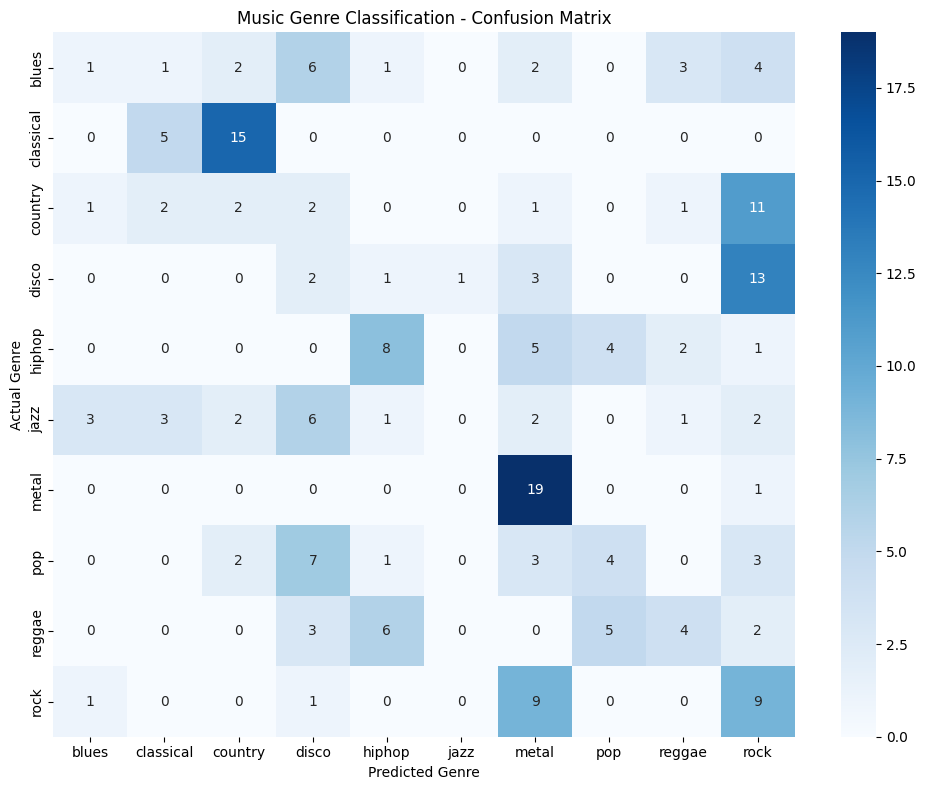

In [31]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.title("Music Genre Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

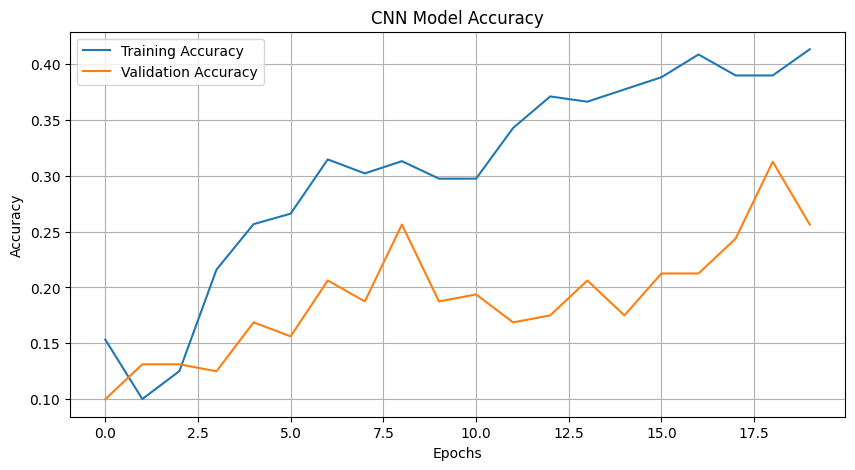

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

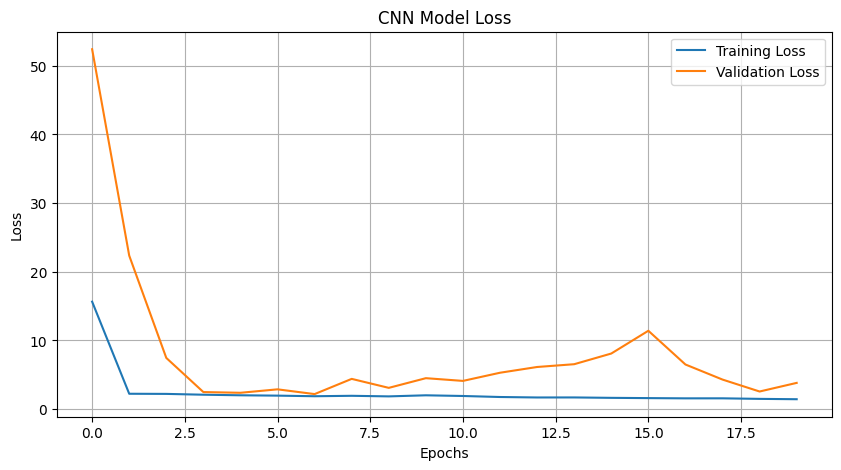

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [34]:
model.save("music_genre_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [35]:
from google.colab import files

files.download("music_genre_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
from google.colab import files

uploaded = files.upload()

Saving music_genre_cnn.keras to music_genre_cnn (1).keras


In [39]:
import os

test_audio_path = "/content/gtzan/Data/genres_original/blues/blues.00001.wav"

print("Audio file exists:", os.path.exists(test_audio_path))

Audio file exists: True


In [40]:
import librosa
import numpy as np

# Load the audio file
audio, sr = librosa.load(
    test_audio_path,
    sr=22050,
    duration=10
)

# Generate Mel Spectrogram
mel_spec = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_mels=128,
    n_fft=2048,
    hop_length=512
)

# Convert to decibels
mel_spec_db = librosa.power_to_db(
    mel_spec,
    ref=np.max
)

# Prepare input for CNN
input_data = mel_spec_db[np.newaxis, ..., np.newaxis]

# Predict genre
prediction = model.predict(input_data)
predicted_class = np.argmax(prediction, axis=1)[0]

# Display result
predicted_genre = label_encoder.inverse_transform(
    [predicted_class]
)[0]

print("Predicted Music Genre:", predicted_genre)
print("Prediction Confidence:", round(np.max(prediction) * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
Predicted Music Genre: disco
Prediction Confidence: 26.59 %
